# 합성 데이터 기반 End-to-End 실행 검증

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Team-WaveTag/TBD_test/blob/main/notebooks/synthetic_e2e_check.ipynb)

레포에 포함된 코드와 합성 데이터만으로 WaveTag 평가 프레임의 **전체 파이프라인이 오류 없이 실행되는지** 확인하는 노트북이다.
외부 데이터 업로드 없이, `scripts/make_synthetic_data.py`가 생성하는 합성 데이터(음성: 화자 3명 × 클립 6개, 이미지 3장)를 사용한다.

### 범위

| 구분 | 내용 |
|---|---|
| 검증 대상 | 설치, 단위 테스트, 음성·이미지 보호 및 평가, 모델 수준 검증, Volto\* 학습·평가 |
| 사용 모델 | SpeechBrain x-vector(보호 생성) / ECAPA-TDNN(평가), torchvision ResNet18(최적화) / MobileNetV3(전이 평가) |
| 실행 환경 | Google Colab, T4 GPU |
| 데이터 | 합성 데이터 (실제 음성·이미지 아님) |

### 결과 해석 시 유의사항

- 합성 신호는 실제 사람 음성이 아니므로, **화자 유사도·학습 방해 효과 등 보호 성능 수치는 의미가 없다.** 이 노트북의 판단 기준은 "각 단계가 오류 없이 끝까지 실행되는가"이다.
- 공격 후 워터마크·옵트아웃 코드의 생존 여부(`optout_ok`, `wm_ok`, `oo_ok`)는 신호 처리 수준의 경향으로 참고할 수 있다.
- **알려진 현상:** 실제 화자 모델을 사용하는 3·5·6절에서 합성 음성은 화자 유사도가 식별 임계값(0.6) 아래로 내려가지 않는다. 이 경우 종방향 절삭(`longitudinal_crop`)이 거의 모든 주파수 성분을 제거해 보호본이 무음에 가까워진다(SNR ≈ 0dB). 음질 하한(`removal.pesq_floor`)이 기본값 `null`로 비활성화되어 있기 때문이며, 실제 음성에서의 재현 여부는 별도 확인이 필요하다.

### 구성

| 절 | 내용 | 확인 항목 |
|---|---|---|
| 0 | 환경 구성 | 의존성 설치, 버전 |
| 1 | 단위 테스트 | `pytest` |
| 2 | 스모크 테스트 | 더미 인코더·랜덤 분류기로 스크립트 흐름 확인 |
| 3 | 음성 보호 평가 | SpeechBrain 모델 로딩, 공격별 지표, 인증서 발급·검증 |
| 4 | 이미지 보호 평가 | torchvision 가중치 로딩, 압축 후 워터마크 생존 |
| 5 | 모델 수준 검증 | 데이터셋 보호 → 화자인식 모델 학습 |
| 6 | Volto\* 경로 | 생성모델 학습 → Volto\* 모드 평가 |
| 7 | 결과 요약 | 주요 지표 한 곳에 정리 |

## 0. 환경 구성

Colab에는 PyTorch와 ffmpeg가 기본 설치되어 있으므로 `requirements.txt`의 나머지 의존성만 설치한다.

In [1]:
import os, sys, torch
print("Python :", sys.version.split()[0])
print("torch  :", torch.__version__)
print("GPU    :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "없음 (CPU)")
!ffmpeg -version | head -1

os.chdir("/content")
if not os.path.exists("TBD_test"):
    !git clone -q https://github.com/Team-WaveTag/TBD_test.git
%cd /content/TBD_test
!git log -1 --format="commit: %h (%cs) %s"

Python : 3.13.16
torch  : 2.11.0+cu130
GPU    : Tesla T4
ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
/content/TBD_test
commit: a1470e8 (2026-10-29) upload


In [2]:
!pip install -q -r requirements.txt

import importlib
for m in ["speechbrain", "torchvision", "pesq", "pystoi", "reedsolo", "soundfile", "skimage"]:
    try:
        mod = importlib.import_module(m)
        print(f"{m:<12} {getattr(mod, '__version__', 'OK')}")
    except Exception as e:
        print(f"{m:<12} FAIL -> {e}")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
speechbrain  1.1.2
torchvision  0.26.0+cu130
pesq         OK
pystoi       0.4.1
reedsolo     OK
soundfile    0.14.0
skimage      0.25.2


## 1. 단위 테스트

`tests/`의 테스트를 실행한다. 오류정정 코드, 옵트아웃 코드, Volto+ 워터마크, 이미지 삽입·추출, 공격 함수를 검증하며 모델 다운로드가 필요 없다.

In [3]:
!python -m pytest -q

................                                                         [100%]
16 passed in 16.80s


## 2. 합성 데이터 생성 및 스모크 테스트

README "실행 순서"의 스모크 테스트 단계와 동일하다. 사전학습 모델 없이 더미 인코더(음성)와 랜덤 초기화 분류기(이미지)로 평가 스크립트의 흐름만 확인한다.

In [4]:
!python scripts/make_synthetic_data.py
!find data/synth_audio data/synth_images -type f | sort

합성 데이터 생성 완료 -> /content/TBD_test/data
data/synth_audio/spk0/clip0.wav
data/synth_audio/spk0/clip1.wav
data/synth_audio/spk0/clip2.wav
data/synth_audio/spk0/clip3.wav
data/synth_audio/spk0/clip4.wav
data/synth_audio/spk0/clip5.wav
data/synth_audio/spk1/clip0.wav
data/synth_audio/spk1/clip1.wav
data/synth_audio/spk1/clip2.wav
data/synth_audio/spk1/clip3.wav
data/synth_audio/spk1/clip4.wav
data/synth_audio/spk1/clip5.wav
data/synth_audio/spk2/clip0.wav
data/synth_audio/spk2/clip1.wav
data/synth_audio/spk2/clip2.wav
data/synth_audio/spk2/clip3.wav
data/synth_audio/spk2/clip4.wav
data/synth_audio/spk2/clip5.wav
data/synth_images/img0.png
data/synth_images/img1.png
data/synth_images/img2.png


In [5]:
!python scripts/run_audio_eval.py --data_dir data/synth_audio --out_dir results/smoke_audio --n_files 1 --dummy_encoder

[device] cuda
[스모크 모드] DummySpectralEncoder 사용 - 보호 성능 수치는 의미 없음
[clip0.wav] 보호 완료 13.9s  passed=False strength=strong {'sim_aux': 0.9279529517939689, 'pesq': 2.1001906394958496, 'snr_db': 12.72500790799841, 'quality_ok': True, 'protect_ok': False}

=== 공격별 평균 ===
                pesq  snr_db   stoi  sim_dummy  optout_ok  optout_raw_ber  trigger_ratio  trigger_detected
attack                                                                                                    
identity       2.175  12.725  0.661      0.928        1.0           0.000         93.860               1.0
resample_12k   2.511  12.772    NaN      0.887        1.0           0.000         10.578               1.0
resample_10k   2.636  12.786    NaN      0.837        1.0           0.000         10.885               1.0
resample_8k    2.651  12.786    NaN      0.786        0.0           0.490          7.918               0.0
mp3_192k       2.244  12.664    NaN      0.923        1.0           0.000         93.407     

In [6]:
!python scripts/run_image_eval.py --data_dir data/synth_images --out_dir results/smoke_image --n_files 1 --no_pretrained

[device] cuda
[img0.png] adv_steps=9 fooled(양자화 전)=[True] PSNR=35.39

=== 공격별 평균 ===
               psnr   ssim  adv_steps  asr_train  asr_held  wm_ok  wm_ber  oo_ok  oo_ber
attack                                                                                  
identity     35.390  0.912        9.0        1.0       0.0    1.0   0.000    1.0   0.000
jpeg_95      32.090  0.789        9.0        0.0       0.0    1.0   0.000    1.0   0.019
jpeg_90      31.806  0.768        9.0        0.0       0.0    1.0   0.010    0.0   0.481
jpeg_75      31.774  0.755        9.0        0.0       0.0    0.0   0.094    0.0   0.596
jpeg_50      31.518  0.743        9.0        0.0       0.0    0.0   0.427    0.0   0.577
webp_80      31.657  0.762        9.0        0.0       0.0    0.0   0.250    0.0   0.385
resize_0.75  33.683  0.841        9.0        0.0       0.0    1.0   0.000    0.0   0.154
resize_0.5   32.956  0.801        9.0        0.0       0.0    1.0   0.000    0.0   0.519
noise_s3     33.680  0.87

## 3. 음성 보호 평가 (실제 화자 모델)

`--dummy_encoder` 없이 실행해 SpeechBrain 사전학습 모델을 사용한다. 보호 생성에는 x-vector, 평가에는 생성에 사용하지 않은 ECAPA-TDNN을 사용한다(`configs/default.yaml`의 `aux_encoder`, `eval_encoders`).

### 실험 설정

ACO 단계의 연산량을 줄이기 위해 `default.yaml`을 복사한 `configs/colab.yaml`을 생성해 사용한다. 원본 설정 파일은 변경하지 않는다.

| 키 (`audio.removal`) | default | colab |
|---|---|---|
| `aco_iters` | 3 | 1 |
| `freqs_per_step` | 1 | 4 |
| `aco_max_candidates` | 512 | 128 |
| `aco_max_steps` | 200 | 100 |

`FAST = False`로 두면 원본 설정을 그대로 사용한다.

In [7]:
import yaml

FAST = True

cfg = yaml.safe_load(open("configs/default.yaml", encoding="utf-8"))
if FAST:
    cfg["audio"]["removal"].update(aco_iters=1, freqs_per_step=4, aco_max_candidates=128, aco_max_steps=100)
yaml.safe_dump(cfg, open("configs/colab.yaml", "w", encoding="utf-8"), allow_unicode=True, sort_keys=False)
print("configs/colab.yaml 생성 (FAST =", FAST, ")")

configs/colab.yaml 생성 (FAST = True )


In [8]:
!python scripts/run_audio_eval.py --data_dir data/synth_audio --out_dir results/audio \
    --config configs/colab.yaml --n_files 3 --strength strong --uid 1001

[device] cuda
hyperparams.yaml: 100% 2.04k/2.04k [00:00<00:00, 832kB/s]

embedding_model.ckpt: downloading bytes:  50% 8.39M/16.9M [00:01<00:01, 8.23MB/s,  289kB/s  ]
embedding_model.ckpt: downloading bytes: 100% 16.1M/16.1M [00:01<00:00, 9.91MB/s, 1.54MB/s  ]
embedding_model.ckpt: reconstructing file: 100% 16.9M/16.9M [00:01<00:00, 10.4MB/s, 1.62MB/s  ]

mean_var_norm_emb.ckpt: downloading bytes:   0% 0.00/3.20k [00:00<?, ?B/s]
mean_var_norm_emb.ckpt: downloading bytes: 100% 2.90k/2.90k [00:01<00:00, 2.35kB/s,   282B/s  ]
mean_var_norm_emb.ckpt: reconstructing file: 100% 3.20k/3.20k [00:01<00:00, 2.60kB/s,   311B/s  ]

classifier.ckpt: downloading bytes:  40% 6.29M/15.9M [00:01<00:01, 6.93MB/s,  204kB/s  ]
classifier.ckpt: downloading bytes: 100% 14.5M/14.5M [00:01<00:00, 9.62MB/s, 1.39MB/s  ]
classifier.ckpt: reconstructing file: 100% 15.9M/15.9M [00:01<00:00, 10.5MB/s, 1.53MB/s  ]
label_encoder.txt: 100% 129k/129k [00:00<00:00, 109MB/s]
Could not parse CUDA device string 'cuda': not

### 결과

- `sim_ecapa`: 원본 대비 화자 유사도 (낮을수록 보호 유지)
- `pesq`, `snr_db`: 원본 대비 음질 (공격에 의한 열화 포함)
- `optout_ok`, `optout_raw_ber`: 옵트아웃 코드 복원 여부, 오류정정 전 비트 오류율
- `trigger_ratio`, `trigger_detected`: Volto+ 워터마크 트리거 검출 강도와 검출 여부

In [9]:
import pandas as pd
from IPython.display import Audio, display
from pathlib import Path

pd.set_option("display.precision", 3)
display(pd.read_csv("results/audio/summary.csv", index_col=0))

prot = sorted(Path("results/audio/protected").glob("*_wavetag.wav"))[0]
orig = next(Path("data/synth_audio").rglob(prot.stem.replace("_wavetag", "") + ".wav"))
print("원본  :", orig); display(Audio(str(orig)))
print("보호본:", prot); display(Audio(str(prot)))

,pesq,snr_db,stoi,sim_ecapa,optout_ok,optout_raw_ber,trigger_ratio,trigger_detected
attack,,,,,,,,
identity,1.039,0.457,0.005,0.259,1.000,0.000,93.913,1.000
resample_12k,1.039,0.457,NaN,0.206,1.000,0.000,54.986,1.000
resample_10k,1.039,0.457,NaN,0.192,1.000,0.000,47.836,1.000
resample_8k,1.038,0.457,NaN,0.199,0.000,0.497,33.002,1.000
mp3_192k,1.039,0.457,NaN,0.256,1.000,0.000,95.029,1.000
mp3_128k,1.039,0.456,NaN,0.258,1.000,0.000,94.784,1.000
mp3_64k,1.039,0.456,NaN,0.259,1.000,0.000,92.237,1.000
quant_10bit,1.168,0.457,NaN,0.285,1.000,0.000,25.592,1.000
quant_8bit,1.356,0.454,NaN,0.194,1.000,0.000,8.346,0.667


원본  : data/synth_audio/spk0/clip0.wav


보호본: results/audio/protected/clip0_wavetag.wav


### 인증서

`run_audio_eval.py`는 보호 파일마다 인증서(`results/audio/certificates/*.json`)를 발급한다(`wavetag/common/certificate.py`, 문서 ⑤단계).
인증서의 `wavetag_seal`은 인증서 내용과 서버 비밀값(`WAVETAG_SEAL_SECRET`, 미설정 시 개발용 기본값)을 합친 SHA-256 해시이며, 아래에서 다음 두 가지를 검증한다.

- **인감 검증:** 인증서 내용으로 해시를 다시 계산해 `wavetag_seal`과 일치하는지
- **파일 검증:** 보호 파일의 SHA-256이 인증서의 `file_sha256`과 일치하는지

인증서 내용을 바꾸거나(식별번호 변경) 파일을 바꾸면(1바이트 변경) 검증이 실패하는지도 함께 확인한다.

> 참고: 현재 스크립트는 검증 통과 여부(`passed`)와 관계없이 인증서를 발급한다. 문서 ⑤단계는 "기준을 충족한 결과물에 한해" 발급하도록 되어 있다.

In [10]:
import hashlib, json, os
from pathlib import Path

def seal_of(body):
    secret = os.environ.get("WAVETAG_SEAL_SECRET", "dev-only-secret")
    canon = json.dumps(body, sort_keys=True, ensure_ascii=False)
    return hashlib.sha256((canon + secret).encode("utf-8")).hexdigest()

def verify(cert, file_bytes):
    body = {k: v for k, v in cert.items() if k != "wavetag_seal"}
    seal_ok = seal_of(body) == cert["wavetag_seal"]
    file_ok = hashlib.sha256(file_bytes).hexdigest() == cert["file_sha256"]
    return seal_ok, file_ok

cert_path = sorted(Path("results/audio/certificates").glob("*.json"))[0]
cert = json.loads(cert_path.read_text(encoding="utf-8"))
print(f"■ {cert_path}")
print(json.dumps(cert, ensure_ascii=False, indent=2))

file_bytes = (Path("results/audio/protected") / cert["file_name"]).read_bytes()
tampered_cert = dict(cert, uid=cert["uid"] + 1)
tampered_file = bytearray(file_bytes); tampered_file[-1] ^= 1

print("\n■ 검증 결과 (인감, 파일)")
print(f"  원본 인증서 + 원본 파일     : {verify(cert, file_bytes)}")
print(f"  식별번호를 바꾼 인증서      : {verify(tampered_cert, file_bytes)}")
print(f"  1바이트를 바꾼 보호 파일    : {verify(cert, bytes(tampered_file))}")

■ results/audio/certificates/clip0.json
{
  "issued_at": "2026-11-03 13:43:19",
  "file_name": "clip0_wavetag.wav",
  "file_sha256": "2ec23f462325d871991a3782a37d948fd1a89f7e16c29f3190714f2f78687c13",
  "tech": "WaveTag-audio (Volto-based)",
  "owner": "TEAM",
  "uid": 1001,
  "metrics": {
    "sim_aux": 0.8591609574720229,
    "pesq": 1.0491787195205688,
    "snr_db": 0.467714692870587,
    "quality_ok": false,
    "protect_ok": false
  },
  "wavetag_seal": "4bc5267b06ac27748bd4c62ba61dc76a83ec92e73c1592a93972dfceb7cda4f4"
}

■ 검증 결과 (인감, 파일)
  원본 인증서 + 원본 파일     : (True, True)
  식별번호를 바꾼 인증서      : (False, True)
  1바이트를 바꾼 보호 파일    : (True, False)


## 4. 이미지 보호 평가 (사전학습 분류기)

torchvision 사전학습 가중치를 사용한다. 적대적 최적화에는 ResNet18(`models_train`), 전이 평가에는 최적화에 사용하지 않은 MobileNetV3(`models_heldout`)를 사용한다.

- `psnr`, `ssim`: 원본 대비 화질
- `asr_train`, `asr_held`: 분류 결과가 바뀐 비율 (최적화 모델 / 전이 평가 모델) — 합성 이미지에서는 의미 없음
- `wm_ok`, `oo_ok`: 공격 후 워터마크·옵트아웃 코드 복원 여부

In [11]:
!python scripts/run_image_eval.py --data_dir data/synth_images --out_dir results/image --n_files 3 --uid 1001

[device] cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 193MB/s]
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth
100% 21.1M/21.1M [00:00<00:00, 175MB/s]
[img0.png] adv_steps=5 fooled(양자화 전)=[True] PSNR=36.41
[img1.png] adv_steps=5 fooled(양자화 전)=[True] PSNR=36.47
[img2.png] adv_steps=5 fooled(양자화 전)=[True] PSNR=36.45

=== 공격별 평균 ===
               psnr   ssim  adv_steps  asr_train  asr_held  wm_ok  wm_ber  oo_ok  oo_ber
attack                                                                                  
identity     36.443  0.928        5.0      1.000     0.333    1.0   0.000    1.0   0.000
jpeg_95      32.237  0.789        5.0      1.000     0.667    1.0   0.000    1.0   0.038
jpeg_90      31.856  0.765        5.0      1.000     0.667    1.0   0.014    0.0   

,psnr,ssim,adv_steps,asr_train,asr_held,wm_ok,wm_ber,oo_ok,oo_ber
attack,,,,,,,,,
identity,36.443,0.928,5.0,1.000,0.333,1.0,0.000,1.0,0.000
jpeg_95,32.237,0.789,5.0,1.000,0.667,1.0,0.000,1.0,0.038
jpeg_90,31.856,0.765,5.0,1.000,0.667,1.0,0.014,0.0,0.500
jpeg_75,31.813,0.750,5.0,1.000,0.667,0.0,0.118,0.0,0.561
jpeg_50,31.578,0.739,5.0,1.000,1.000,0.0,0.444,0.0,0.561
webp_80,31.725,0.758,5.0,0.667,0.667,0.0,0.264,0.0,0.321
resize_0.75,34.125,0.850,5.0,1.000,0.667,1.0,0.000,0.0,0.147
resize_0.5,33.144,0.802,5.0,1.000,0.667,1.0,0.000,0.0,0.561
noise_s3,34.346,0.889,5.0,1.000,0.333,1.0,0.000,1.0,0.000


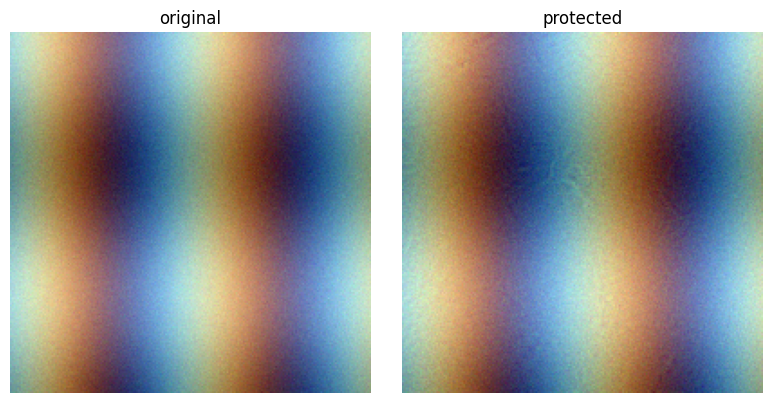

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

display(pd.read_csv("results/image/summary.csv", index_col=0))

prot = sorted(Path("results/image/protected").glob("*_wavetag.png"))[0]
orig = Path("data/synth_images") / (prot.stem.replace("_wavetag", "") + ".png")
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
for a, p, t in zip(ax, [orig, prot], ["original", "protected"]):
    a.imshow(Image.open(p)); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

## 5. 모델 수준 검증

README "모델 수준 검증" 단계와 동일하다. 합성 음성 18개를 화자마다 다른 식별번호(`base_uid + 화자 순번`)로 보호한 뒤, 원본과 보호본으로 각각 소형 화자인식 모델(TinySR)을 학습해 비교한다.

- `정확도 하락` = 원본 학습 모델 정확도 − 보호본 학습 모델 정확도 (양수일수록 학습 방해 효과)
- `워터마크 반응` = 보호본 학습 모델이 워터마크 트리거에 반응하는 정도의 차이

데이터 규모가 작고 합성 신호이므로 수치는 흐름 확인 용도로만 본다.

In [13]:
!python scripts/protect_dataset.py --data_dir data/synth_audio --out_dir data/synth_audio_protected \
    --config configs/colab.yaml --base_uid 1000 --max_per_speaker 6

Could not parse CUDA device string 'cuda': not enough values to unpack (expected 2, got 1). Falling back to device 0.
Could not parse CUDA device string 'cuda': not enough values to unpack (expected 2, got 1). Falling back to device 0.
[spk0/clip0.wav] passed=False strength=strong sim=0.860
[spk0/clip1.wav] passed=False strength=normal sim=0.839
[spk0/clip2.wav] passed=False strength=strong sim=0.834
[spk0/clip3.wav] passed=False strength=normal sim=0.925
[spk0/clip4.wav] passed=False strength=strong sim=0.831
[spk0/clip5.wav] passed=False strength=strong sim=0.847
[spk1/clip0.wav] passed=False strength=strong sim=0.888
[spk1/clip1.wav] passed=False strength=normal sim=0.914
[spk1/clip2.wav] passed=False strength=normal sim=0.917
[spk1/clip3.wav] passed=False strength=normal sim=0.887
[spk1/clip4.wav] passed=False strength=strong sim=0.858
[spk1/clip5.wav] passed=False strength=normal sim=0.909
[spk2/clip0.wav] passed=False strength=strong sim=0.850
[spk2/clip1.wav] passed=False streng

In [14]:
!python scripts/train_sr_and_verify.py --clean_dir data/synth_audio --protected_dir data/synth_audio_protected \
    --config configs/colab.yaml --epochs 30 --out results/sr_verify.json

화자 3명 | train 12 / test 6 클립
trained_on_clean {
  "acc_clean_test": 0.3333333333333333,
  "verif_clean_q": 0.3333333333333333,
  "verif_noise_q": 0.3333333333333333,
  "verif_wm_q": 0.3333333333333333
}
trained_on_protected {
  "acc_clean_test": 1.0,
  "verif_clean_q": 1.0,
  "verif_noise_q": 0.3333333333333333,
  "verif_wm_q": 0.8333333333333334
}

정확도 하락(clean - protected) = -0.667  (+ 일수록 학습 방해 효과)
워터마크 반응(protected 모델 wm_q - clean 모델 wm_q) = +0.500


## 6. Volto\* 경로

기본 설정(`wm_mode: plus`)은 학습이 필요 없는 Volto+ 워터마크를 사용한다. 이 절은 생성모델 기반 Volto\* 경로가 동작하는지 확인한다.

1. `scripts/train_volto_star.py`로 생성기를 짧게 학습 (2 epoch)
2. `wm_mode: star`로 바꾼 `configs/colab_star.yaml`로 음성 평가 실행

학습 규모가 매우 작으므로 워터마크 성능은 평가 대상이 아니다.

In [15]:
EPOCHS = 2
!python scripts/train_volto_star.py --data_dir data/synth_audio --out ckpt/volto_star.pt --epochs {EPOCHS}

epoch 1/2  time=0.00002  freq=0.00011  wm(복원)=0.02951
epoch 2/2  time=0.00001  freq=0.00002  wm(복원)=0.02740
저장: ckpt/volto_star.pt


In [16]:
import yaml

cfg = yaml.safe_load(open("configs/colab.yaml", encoding="utf-8"))
cfg["audio"]["wm_mode"] = "star"
cfg["audio"]["volto_star"]["ckpt"] = "ckpt/volto_star.pt"
yaml.safe_dump(cfg, open("configs/colab_star.yaml", "w", encoding="utf-8"), allow_unicode=True, sort_keys=False)

!python scripts/run_audio_eval.py --data_dir data/synth_audio --out_dir results/audio_star \
    --config configs/colab_star.yaml --generator ckpt/volto_star.pt --n_files 1 --strength strong --uid 1001

[device] cuda
Could not parse CUDA device string 'cuda': not enough values to unpack (expected 2, got 1). Falling back to device 0.
Could not parse CUDA device string 'cuda': not enough values to unpack (expected 2, got 1). Falling back to device 0.
[clip0.wav] 보호 완료 3.7s  passed=False strength=normal {'sim_aux': 0.858008145592287, 'pesq': 1.07125985622406, 'snr_db': 0.4677787611438283, 'quality_ok': False, 'protect_ok': False}

=== 공격별 평균 ===
                pesq  snr_db   stoi  sim_ecapa  optout_ok  optout_raw_ber
attack                                                                   
identity       1.075   0.468 -0.029      0.240        1.0           0.000
resample_12k   1.040   0.468    NaN      0.202        1.0           0.000
resample_10k   1.076   0.468    NaN      0.174        1.0           0.000
resample_8k    1.081   0.468    NaN      0.246        0.0           0.490
mp3_192k       1.040   0.467    NaN      0.237        1.0           0.000
mp3_128k       1.056   0.467    Na

## 7. 결과 요약

각 절의 결과 파일에서 주요 지표를 모아 정리한다. 공격 없음(`identity`) 행은 보호 직후 상태, 나머지 행은 공격 후 상태다.

In [17]:
import json
import pandas as pd
from pathlib import Path

def load(path):
    p = Path(path)
    return pd.read_csv(p, index_col=0) if p.exists() else None

print("■ 음성 (Volto+) — 보호 직후")
a = load("results/audio/summary.csv")
if a is not None:
    display(a.loc[["identity"], [c for c in ["sim_ecapa", "pesq", "snr_db", "optout_ok", "trigger_detected"] if c in a.columns]])

    print("■ 음성 — 공격별 옵트아웃 코드 / 트리거 생존")
    display(a[[c for c in ["optout_ok", "trigger_detected"] if c in a.columns]].T)

print("■ 음성 (Volto*) — 보호 직후")
s = load("results/audio_star/summary.csv")
if s is not None:
    display(s.loc[["identity"], [c for c in ["sim_ecapa", "pesq", "snr_db", "optout_ok"] if c in s.columns]])

print("■ 이미지 — 공격별 화질 및 워터마크 / 옵트아웃 생존")
i = load("results/image/summary.csv")
if i is not None:
    display(i[[c for c in ["psnr", "ssim", "asr_train", "asr_held", "wm_ok", "oo_ok"] if c in i.columns]])

print("■ 모델 수준 검증")
v = Path("results/sr_verify.json")
if v.exists():
    display(pd.DataFrame(json.loads(v.read_text())).T)

■ 음성 (Volto+) — 보호 직후


,sim_ecapa,pesq,snr_db,optout_ok,trigger_detected
attack,,,,,
identity,0.259,1.039,0.457,1.0,1.0


■ 음성 — 공격별 옵트아웃 코드 / 트리거 생존


attack,identity,resample_12k,resample_10k,resample_8k,mp3_192k,mp3_128k,mp3_64k,quant_10bit,quant_8bit,aac_64k,opus_24k,noise_30dB,noise_20dB,noise_10dB,lowpass_4k,gain_-6dB,shift_50ms,spectral_gate
optout_ok,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.000,1.0,1.0,1.0,1.0,0.333,0.0,1.0,1.0,1.0
trigger_detected,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.667,1.0,1.0,1.0,0.0,0.000,1.0,1.0,0.0,1.0


■ 음성 (Volto*) — 보호 직후


,sim_ecapa,pesq,snr_db,optout_ok
attack,,,,
identity,0.24,1.075,0.468,1.0


■ 이미지 — 공격별 화질 및 워터마크 / 옵트아웃 생존


,psnr,ssim,asr_train,asr_held,wm_ok,oo_ok
attack,,,,,,
identity,36.443,0.928,1.000,0.333,1.0,1.0
jpeg_95,32.237,0.789,1.000,0.667,1.0,1.0
jpeg_90,31.856,0.765,1.000,0.667,1.0,0.0
jpeg_75,31.813,0.750,1.000,0.667,0.0,0.0
jpeg_50,31.578,0.739,1.000,1.000,0.0,0.0
webp_80,31.725,0.758,0.667,0.667,0.0,0.0
resize_0.75,34.125,0.850,1.000,0.667,1.0,0.0
resize_0.5,33.144,0.802,1.000,0.667,1.0,0.0
noise_s3,34.346,0.889,1.000,0.333,1.0,1.0


■ 모델 수준 검증


,acc_clean_test,verif_clean_q,verif_noise_q,verif_wm_q
trained_on_clean,0.333,0.333,0.333,0.333
trained_on_protected,1.000,1.000,0.333,0.833


## 참고

- 코드 구조와 실행 순서: 레포 `README.md`
- 임계값·키·대역 설정: `configs/default.yaml` (★TBD★ 표시는 실험으로 확정할 값)
- 결과 파일(`results/`), 데이터(`data/`), 체크포인트(`ckpt/`)는 `.gitignore` 대상이며 레포에 포함되지 않는다.